In [ ]:
# First, we need to install pycocotools. This library will be used for computing the evaluation metrics following the COCO metric for intersection over union.
# The version by default in Colab has a bug fixed in https://github.com/cocodataset/cocoapi/pull/354
!pip install cython
!pip install -U 'git+https://github.com/cocodataset/cocoapi.git#subdirectory=PythonAPI'

  Cloning https://github.com/cocodataset/cocoapi.git to /tmp/pip-req-build-k0deaivv
  Running command git clone -q https://github.com/cocodataset/cocoapi.git /tmp/pip-req-build-k0deaivv
  Created wheel for pycocotools: filename=pycocotools-2.0-cp37-cp37m-linux_x86_64.whl size=263896 sha256=928847f5fd97391cbe1866b0037de6bf0cbfa2224784391b172371c5e7738f3f
  Stored in directory: /tmp/pip-ephem-wheel-cache-pu73a0dz/wheels/90/51/41/646daf401c3bc408ff10de34ec76587a9b3ebfac8d21ca5c3a
Successfully built pycocotools
  Found existing installation: pycocotools 2.0
    Uninstalling pycocotools-2.0:
      Successfully uninstalled pycocotools-2.0


In [1]:
import json
import math
import os
import random
import sys
import time

import numpy as np
import torch
import torch.utils.data
import torchvision

from PIL import Image, ImageDraw
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torchvision import transforms
from torchvision.ops import batched_nms
from torchvision.transforms import functional as F

In [2]:
from typing import List, Tuple

import torchvision.models as models

from torchvision.models.detection.backbone_utils import resnet_fpn_backbone
from torchvision.models.detection.faster_rcnn import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator
from torchvision.ops import MultiScaleRoIAlign

In [3]:
%%shell

# Download TorchVision repo to use some files from references/detection
git clone https://github.com/pytorch/vision.git
cd vision
git checkout v0.3.0

cp references/detection/utils.py ../
cp references/detection/coco_eval.py ../

Cloning into 'vision'...
remote: Enumerating objects: 28095, done.
remote: Counting objects: 100% (641/641), done.
remote: Compressing objects: 100% (235/235), done.
remote: Total 28095 (delta 467), reused 530 (delta 398), pack-reused 27454
Receiving objects: 100% (28095/28095), 36.12 MiB | 33.72 MiB/s, done.
Resolving deltas: 100% (21079/21079), done.
Note: checking out 'v0.3.0'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by performing another checkout.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -b with the checkout command again. Example:

  git checkout -b <new-branch-name>

HEAD is now at be376084 version check against PyTorch's CUDA version


In [4]:
import utils
from coco_eval import CocoEvaluator

In [5]:
# check if cuda GPU is available, make sure you're using GPU runtime on Google Colab
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device) # you should output "cuda"

cuda


In [6]:
# mount your google drive
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


# Object Detection

In [7]:
# You should have uploaded the training dataset onto your google drive.

base_folder = '/content/drive/MyDrive/TIL2021/CV' # Change this path to your folder for this competition
training_path = os.path.join(base_folder, "c1_release.zip") # zip file for training dataset

In [8]:
# unzip the training dataset
!unzip $training_path

Archive:  /content/drive/MyDrive/TIL2021/CV/c1_release.zip
   creating: c1_release/
  inflating: c1_release/val.json     
  inflating: c1_release/train.json   
  inflating: c1_release/labels.json  
  inflating: c1_release/CREDITS.txt  
   creating: c1_release/images/
  inflating: c1_release/images/0dab6f0b8525d425.jpg  
  inflating: c1_release/images/19cc71d55265e083.jpg  
  inflating: c1_release/images/2574278a3406efa9.jpg  
  inflating: c1_release/images/4b2243190b2ae75e.jpg  
  inflating: c1_release/images/984815695c3ca54b.jpg  
  inflating: c1_release/images/0038162a38adaaa8.jpg  
  inflating: c1_release/images/b3750a548fd77a04.jpg  
  inflating: c1_release/images/5117b754613a09a9.jpg  
  inflating: c1_release/images/88488e72c60fcbde.jpg  
  inflating: c1_release/images/89fc506a70c0d39d.jpg  
  inflating: c1_release/images/d06312a3067178c8.jpg  
  inflating: c1_release/images/bfd56ff4bf1c8789.jpg  
  inflating: c1_release/images/485fb30319e9acc2.jpg  
  inflating: c1_release/images

In [9]:
class TILDataset(torch.utils.data.Dataset):
    def __init__(self, root, annotation, transforms=None):
        self.root = root
        self.transforms = transforms
        self.coco = COCO(annotation)
        self.ids = list(sorted(self.coco.imgs.keys()))
        cats = self.coco.loadCats(self.coco.getCatIds())
        self.cat2name = {cat['id']:cat['name'] for cat in cats} # maps category id to category name (useful for visualization)

    def __getitem__(self, index):
        coco = self.coco
        img_id = self.ids[index] # Image ID
        ann_ids = coco.getAnnIds(imgIds=img_id) # get annotation id from coco
        coco_annotation = coco.loadAnns(ann_ids) # target coco_annotation file for an image
        path = coco.loadImgs(img_id)[0]['file_name'] # path for input image
        img = Image.open(os.path.join(self.root, 'images', path)).convert('RGB') # open the input image

        # number of objects in the image
        num_objs = len(coco_annotation)

        # Bounding boxes for objects
        # In coco format, bbox = [xmin, ymin, width, height]
        # In pytorch, the input should be [xmin, ymin, xmax, ymax]
        boxes = []
        for i in range(num_objs):
            xmin = coco_annotation[i]['bbox'][0]
            ymin = coco_annotation[i]['bbox'][1]
            xmax = xmin + coco_annotation[i]['bbox'][2]
            ymax = ymin + coco_annotation[i]['bbox'][3]
            boxes.append([xmin, ymin, xmax, ymax])
        boxes = torch.as_tensor(boxes, dtype=torch.float32)

        # Labels
        labels = []
        for i in range(num_objs):
            labels.append(coco_annotation[i]['category_id'])
        labels = torch.as_tensor(labels, dtype=torch.int64)

        # Tensorise img_id
        img_id = torch.tensor([img_id])

        # Size of bbox (Rectangular)
        areas = []
        for i in range(num_objs):
            areas.append(coco_annotation[i]['area'])
        areas = torch.as_tensor(areas, dtype=torch.float32)

        # suppose all instances are not crowd
        iscrowd = torch.zeros((num_objs,), dtype=torch.int64)

        # Annotation is in dictionary format
        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        target["image_id"] = img_id
        target["area"] = areas
        target["iscrowd"] = iscrowd

        if self.transforms is not None:
            img, target = self.transforms(img, target)

        return img, target

    def __len__(self):
        return len(self.ids)

In [10]:
til_root = "/content/c1_release/" # extracted training dataset path
train_annotation = os.path.join(til_root, "train.json")
val_annotation = os.path.join(til_root, "val.json")

dataset = TILDataset(til_root, train_annotation)
dataset[30]

loading annotations into memory...
Done (t=0.03s)
creating index...
index created!


(<PIL.Image.Image image mode=RGB size=1024x683 at 0x7F4873CEC990>,
 {'area': tensor([ 77211., 309760.]),
  'boxes': tensor([[658., 309., 865., 682.],
          [ 69., 170., 674., 682.]]),
  'image_id': tensor([31]),
  'iscrowd': tensor([0, 0]),
  'labels': tensor([4, 4])})

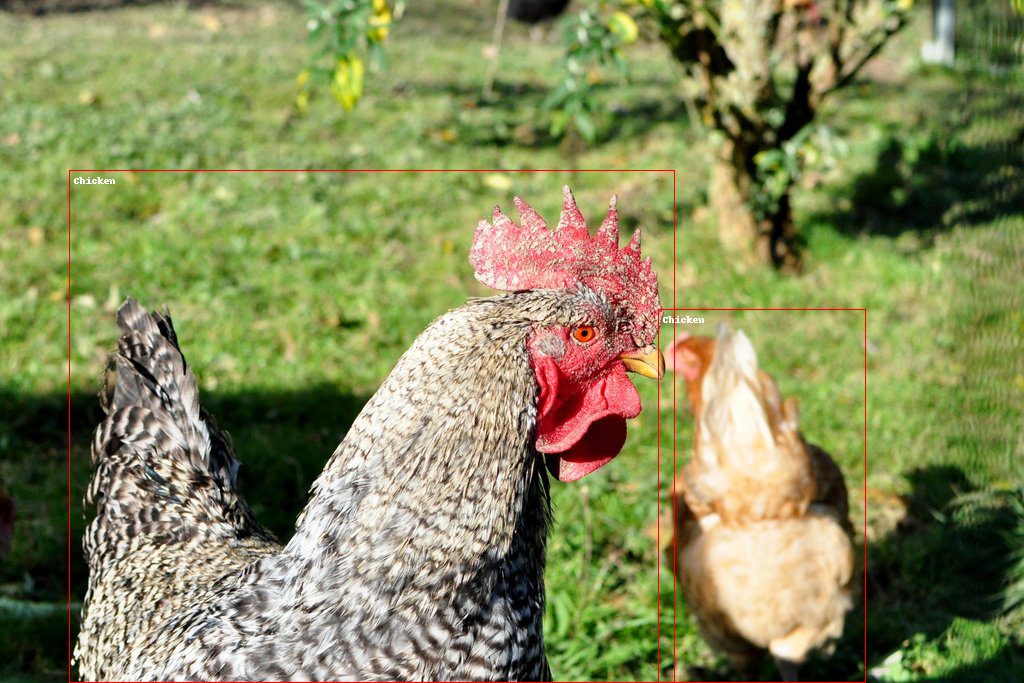

In [11]:
source_img, img_annots = dataset[30]
draw = ImageDraw.Draw(source_img)
for i in range(len(img_annots["boxes"])):
    x1, y1, x2, y2 = img_annots["boxes"][i]
    label = int(img_annots["labels"][i])

    draw.rectangle(((x1, y1), (x2, y2)), outline="red")
    text = f'{dataset.cat2name[label]}'
    draw.text((x1+5, y1+5), text)
display(source_img)

# Model Setup

In [12]:
# hyper-parameters
params = {'BATCH_SIZE': 16,
          'LR': 0.005,
          'CLASSES': 6,
          'MAXEPOCHS': 5,
          'BACKBONE': 'resnet50',
          'FPN': True,
          'ANCHOR_SIZE': ((32,), (64,), (128,), (256,), (512,)),
          'ASPECT_RATIOS': ((0.5, 1.0, 2.0),),
          'MIN_SIZE': 512,
          'MAX_SIZE': 512,
          'IMG_MEAN': [0.485, 0.456, 0.406],
          'IMG_STD': [0.229, 0.224, 0.225],
          'IOU_THRESHOLD': 0.5
          }

In [13]:
def get_resnet_backbone(backbone_name: str):
    """
    Returns a resnet backbone pretrained on ImageNet.
    Removes the average-pooling layer and the linear layer at the end.
    """
    if backbone_name == 'resnet18':
        pretrained_model = models.resnet18(pretrained=True, progress=False)
        out_channels = 512
    elif backbone_name == 'resnet34':
        pretrained_model = models.resnet34(pretrained=True, progress=False)
        out_channels = 512
    elif backbone_name == 'resnet50':
        pretrained_model = models.resnet50(pretrained=True, progress=False)
        out_channels = 2048
    elif backbone_name == 'resnet101':
        pretrained_model = models.resnet101(pretrained=True, progress=False)
        out_channels = 2048
    elif backbone_name == 'resnet152':
        pretrained_model = models.resnet152(pretrained=True, progress=False)
        out_channels = 2048

    backbone = torch.nn.Sequential(*list(pretrained_model.children())[:-2])
    backbone.out_channels = out_channels

    return backbone

In [14]:
def get_resnet_fpn_backbone(backbone_name: str):
    """
    Returns a specified ResNet backbone with FPN pretrained on ImageNet.
    """
    return resnet_fpn_backbone(backbone_name, pretrained=True, trainable_layers=3)

In [15]:
def get_anchor_generator(anchor_size: Tuple[tuple] = None, aspect_ratios: Tuple[tuple] = None):
    """Returns the anchor generator."""
    if anchor_size is None:
        anchor_size = ((16,), (32,), (64,), (128,))
    if aspect_ratios is None:
        aspect_ratios = ((0.5, 1.0, 2.0),) * len(anchor_size)

    anchor_generator = AnchorGenerator(sizes=anchor_size,
                                       aspect_ratios=aspect_ratios)
    return anchor_generator

In [16]:
def get_roi_pool(featmap_names: List[str] = None, output_size: int = 7, sampling_ratio: int = 2):
    """Returns the ROI Pooling"""
    if featmap_names is None:
        # default for resnet with FPN
        featmap_names = ['0', '1', '2', '3']

    roi_pooler = MultiScaleRoIAlign(featmap_names=featmap_names,
                                    output_size=output_size,
                                    sampling_ratio=sampling_ratio)

    return roi_pooler

In [17]:
def get_fasterRCNN(backbone: torch.nn.Module,
                   anchor_generator: AnchorGenerator,
                   roi_pooler: MultiScaleRoIAlign,
                   num_classes: int,
                   image_mean: List[float] = [0.485, 0.456, 0.406],
                   image_std: List[float] = [0.229, 0.224, 0.225],
                   min_size: int = 512,
                   max_size: int = 1024,
                   **kwargs
                   ):
    """Returns the Faster-RCNN model. Default normalization: ImageNet"""
    model = FasterRCNN(backbone=backbone,
                       rpn_anchor_generator=anchor_generator,
                       box_roi_pool=roi_pooler,
                       num_classes=num_classes,
                       image_mean=image_mean,  # ImageNet
                       image_std=image_std,  # ImageNet
                       min_size=min_size,
                       max_size=max_size,
                       **kwargs
                       )
    model.num_classes = num_classes
    model.image_mean = image_mean
    model.image_std = image_std
    model.min_size = min_size
    model.max_size = max_size

    return model

In [18]:
def get_fasterRCNN_resnet(num_classes: int,
                          backbone_name: str,
                          anchor_size: List[float],
                          aspect_ratios: List[float],
                          fpn: bool = True,
                          min_size: int = 512,
                          max_size: int = 1024,
                          **kwargs
                          ):
    """Returns the Faster-RCNN model with resnet backbone with and without fpn."""

    # Backbone
    if fpn:
        backbone = get_resnet_fpn_backbone(backbone_name=backbone_name)
    else:
        backbone = get_resnet_backbone(backbone_name=backbone_name)

    # Anchors
    anchor_size = anchor_size
    aspect_ratios = aspect_ratios * len(anchor_size)
    anchor_generator = get_anchor_generator(anchor_size=anchor_size, aspect_ratios=aspect_ratios)

    # ROI Pool
    with torch.no_grad():
        backbone.eval()
        random_input = torch.rand(size=(1, 3, 512, 512))
        features = backbone(random_input)

    if isinstance(features, torch.Tensor):
        from collections import OrderedDict

        features = OrderedDict([('0', features)])

    featmap_names = [key for key in features.keys() if key.isnumeric()]

    roi_pool = get_roi_pool(featmap_names=featmap_names)

    # Model
    return get_fasterRCNN(backbone=backbone,
                          anchor_generator=anchor_generator,
                          roi_pooler=roi_pool,
                          num_classes=num_classes,
                          min_size=min_size,
                          max_size=max_size,
                          **kwargs)


In [19]:
model = get_fasterRCNN_resnet(num_classes=params['CLASSES'],
                              backbone_name=params['BACKBONE'],
                              anchor_size=params['ANCHOR_SIZE'],
                              aspect_ratios=params['ASPECT_RATIOS'],
                              fpn=params['FPN'],
                              min_size=params['MIN_SIZE'],
                              max_size=params['MAX_SIZE'],
                              image_mean=params['IMG_MEAN'],
                              image_std=params['IMG_STD'])

Downloading: "https://download.pytorch.org/models/resnet50-19c8e357.pth" to /root/.cache/torch/hub/checkpoints/resnet50-19c8e357.pth


In [20]:
# load pretrained weights for FasterRCNN ResNet50 FPN
pretrained_dict = torch.hub.load_state_dict_from_url('https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth', progress=True)
model_dict = model.state_dict()

# filter out roi_heads.box_predictor weights
pretrained_dict = {k: v for k, v in pretrained_dict.items() if not k.startswith('roi_heads.box_predictor')}
# overwrite entries in the existing state dict
model_dict.update(pretrained_dict)
# load the new state dict
model.load_state_dict(model_dict)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


<All keys matched successfully>

In [21]:
# move model to the right device
model.to(device)

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(512,), max_size=512, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=1e-05)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=1e-05)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=1e-05)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=1e-05)
          (relu)

In [22]:
# construct an optimizer
model_params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(model_params, 
                            lr=params['LR'],
                            momentum=0.9, 
                            weight_decay=0.0005)

# and a learning rate scheduler which decreases the learning rate by 10x every 3 epochs
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer,
                                               step_size=3,
                                               gamma=0.1)

# Data Augmentation

In [23]:
class Compose(object):
    def __init__(self, transforms):
        self.transforms = transforms

    def __call__(self, image, target):
        for t in self.transforms:
            image, target = t(image, target)
        return image, target

In [24]:
# converts the image, a PIL image, into a PyTorch Tensor
class ToTensor(object):
    def __call__(self, image, target):
        image = F.to_tensor(image)
        return image, target

In [25]:
# randomly horizontal flip the images and ground-truth labels
class RandomHorizontalFlip(object):
    def __init__(self, prob):
        self.prob = prob

    def __call__(self, image, target):
        if random.random() < self.prob:
            height, width = image.shape[-2:]
            image = image.flip(-1)
            bbox = target["boxes"]
            bbox[:, [0, 2]] = width - bbox[:, [2, 0]]
            target["boxes"] = bbox
        return image, target

In [26]:
class RandomVerticalFlip(object):
    def __init__(self, prob):
        self.prob = prob

    def __call__(self, image, target):
        if random.random() < self.prob:
            height, width = image.shape[-2:]
            image = image.flip(-1)
            bbox = target["boxes"]
            bbox[:, [0, 2]] = width - bbox[:, [2, 0]]
            target["boxes"] = bbox
        return image, target

In [27]:
def get_transform(train):
    if train:
        transforms = Compose([
            ToTensor(), 
            RandomHorizontalFlip(0.5),
            RandomVerticalFlip(0.5)
        ])
    else: # during evaluation, no augmentations will be done
        transforms = Compose([
            ToTensor()
        ])
    
    return transforms

# Data Loader

In [28]:
NUM_WORKERS = 4

# use our dataset and defined transformations
train_dataset = TILDataset(til_root, train_annotation, get_transform(train=True))
val_dataset = TILDataset(til_root, val_annotation, get_transform(train=False))

# define training and validation data loaders
train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=params['BATCH_SIZE'], shuffle=True, num_workers=NUM_WORKERS,
    collate_fn=utils.collate_fn)

val_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=1, shuffle=False, num_workers=NUM_WORKERS,
    collate_fn=utils.collate_fn)

loading annotations into memory...
Done (t=0.03s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


/usr/local/lib/python3.7/dist-packages/torch/utils/data/dataloader.py:477: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  cpuset_checked))


# Model Training

In [29]:
def train_one_epoch(model, optimizer, data_loader, device, epoch, print_freq):
    model.train()
    metric_logger = utils.MetricLogger(delimiter="  ")
    metric_logger.add_meter('lr', utils.SmoothedValue(window_size=1, fmt='{value:.6f}'))
    header = 'Epoch: [{}]'.format(epoch)

    lr_scheduler = None
    if epoch == 0:
        warmup_factor = 1. / 1000
        warmup_iters = min(1000, len(data_loader) - 1)

        lr_scheduler = utils.warmup_lr_scheduler(optimizer, warmup_iters, warmup_factor)

    for images, targets in metric_logger.log_every(data_loader, print_freq, header):
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        loss_value = losses.item()

        if not math.isfinite(loss_value):
            print("Loss is {}, stopping training".format(loss_value))
            print(loss_dict)
            sys.exit(1)

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        if lr_scheduler is not None:
            lr_scheduler.step()

        metric_logger.update(loss=losses, **loss_dict)
        metric_logger.update(lr=optimizer.param_groups[0]["lr"])

In [30]:
@torch.no_grad()
def evaluate(model, data_loader, device):
    n_threads = torch.get_num_threads()
    torch.set_num_threads(1)
    model.eval()
    metric_logger = utils.MetricLogger(delimiter="  ")
    header = 'Test:'

    coco = data_loader.dataset.coco
    iou_types = ["bbox"]
    coco_evaluator = CocoEvaluator(coco, iou_types)

    for image, targets in metric_logger.log_every(data_loader, 100, header):
        image = list(img.to(device) for img in image)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        torch.cuda.synchronize()
        model_time = time.time()
        outputs = model(image)

        outputs = [{k: v for k, v in t.items()} for t in outputs]
        model_time = time.time() - model_time

        res = {target["image_id"].item(): output for target, output in zip(targets, outputs)}
        evaluator_time = time.time()
        coco_evaluator.update(res)
        evaluator_time = time.time() - evaluator_time
        metric_logger.update(model_time=model_time, evaluator_time=evaluator_time)

    # gather the stats from all processes
    metric_logger.synchronize_between_processes()
    print("Averaged stats:", metric_logger)
    coco_evaluator.synchronize_between_processes()

    # accumulate predictions from all images
    coco_evaluator.accumulate()
    coco_evaluator.summarize()
    torch.set_num_threads(n_threads)
    return coco_evaluator


In [31]:
for epoch in range(params['MAXEPOCHS']):
    # train for one epoch, printing every 10 iterations
    train_one_epoch(model, optimizer, train_loader, device, epoch, print_freq=10)

    # update the learning rate
    lr_scheduler.step()

    # evaluate on the test dataset
    evaluate(model, val_loader, device=device)

/usr/local/lib/python3.7/dist-packages/torch/utils/data/dataloader.py:477: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  cpuset_checked))


Epoch: [0]  [  0/263]  eta: 0:37:30  lr: 0.000024  loss: 1.9820 (1.9820)  loss_classifier: 1.7478 (1.7478)  loss_box_reg: 0.2220 (0.2220)  loss_objectness: 0.0092 (0.0092)  loss_rpn_box_reg: 0.0030 (0.0030)  time: 8.5563  data: 6.5851  max mem: 4896
Epoch: [0]  [ 10/263]  eta: 0:09:57  lr: 0.000215  loss: 1.7651 (1.6496)  loss_classifier: 1.5820 (1.4246)  loss_box_reg: 0.1847 (0.1975)  loss_objectness: 0.0149 (0.0236)  loss_rpn_box_reg: 0.0026 (0.0038)  time: 2.3632  data: 0.7475  max mem: 5169
Epoch: [0]  [ 20/263]  eta: 0:08:11  lr: 0.000405  loss: 0.6875 (1.1239)  loss_classifier: 0.4826 (0.8881)  loss_box_reg: 0.2009 (0.2114)  loss_objectness: 0.0151 (0.0209)  loss_rpn_box_reg: 0.0028 (0.0036)  time: 1.6952  data: 0.1425  max mem: 5169
Epoch: [0]  [ 30/263]  eta: 0:07:27  lr: 0.000596  loss: 0.4709 (0.9108)  loss_classifier: 0.2384 (0.6804)  loss_box_reg: 0.1992 (0.2072)  loss_objectness: 0.0152 (0.0190)  loss_rpn_box_reg: 0.0028 (0.0041)  time: 1.6755  data: 0.1295  max mem: 5169


# Data Visualization

In [32]:
# pick one image from the validation set
img, _ = val_dataset[391]

model.eval()
with torch.no_grad():
    prediction = model([img.to(device)])

prediction

[{'boxes': tensor([[527.9562, 175.3481, 896.7780, 756.7734],
          [360.4602, 254.5580, 645.7334, 737.6183],
          [441.8123, 193.2477, 755.4897, 730.1030],
          [ 72.8025,  52.7650, 526.5360, 722.6232],
          [679.9556, 148.2469, 896.1167, 580.5718],
          [ 82.6420,  67.9141, 514.7513, 753.2431],
          [312.6587, 103.3019, 837.7335, 762.8113],
          [527.9333, 227.0140, 866.6148, 757.5511]], device='cuda:0'),
  'labels': tensor([4, 4, 4, 4, 4, 3, 4, 2], device='cuda:0'),
  'scores': tensor([0.9824, 0.9591, 0.8961, 0.8952, 0.5889, 0.4981, 0.2291, 0.0850],
         device='cuda:0')}]

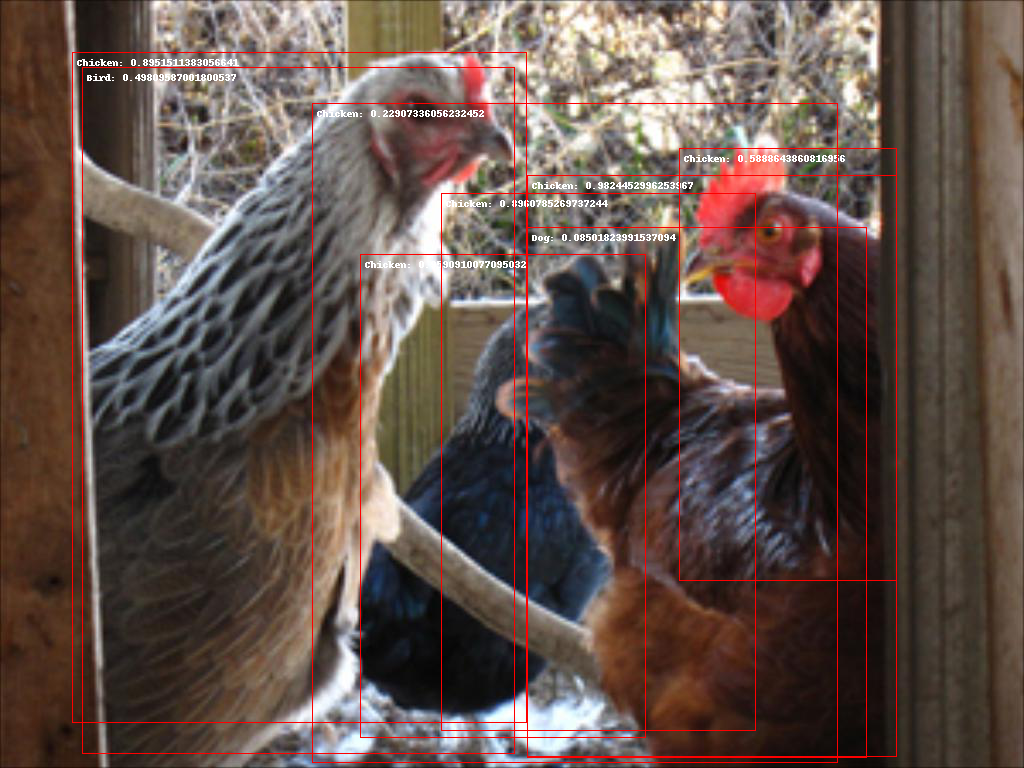

In [33]:
# convert the image, which has been rescaled to 0-1 and had the channels flipped
pred_img = Image.fromarray(img.mul(255).permute(1, 2, 0).byte().numpy())
draw = ImageDraw.Draw(pred_img)

img_preds = prediction[0]
for i in range(len(img_preds["boxes"])):
    x1, y1, x2, y2 = img_preds["boxes"][i]
    label = int(img_preds["labels"][i])
    score = float(img_preds["scores"][i])

    draw.rectangle(((x1, y1), (x2, y2)), outline="red")
    text = f'{dataset.cat2name[label]}: {score}'
    draw.text((x1+5, y1+5), text)

display(pred_img)

# Post Processing

In [34]:
img_preds = prediction[0]
keep_idx = batched_nms(boxes=img_preds["boxes"], scores=img_preds["scores"], idxs=img_preds["labels"], iou_threshold=params['IOU_THRESHOLD'])

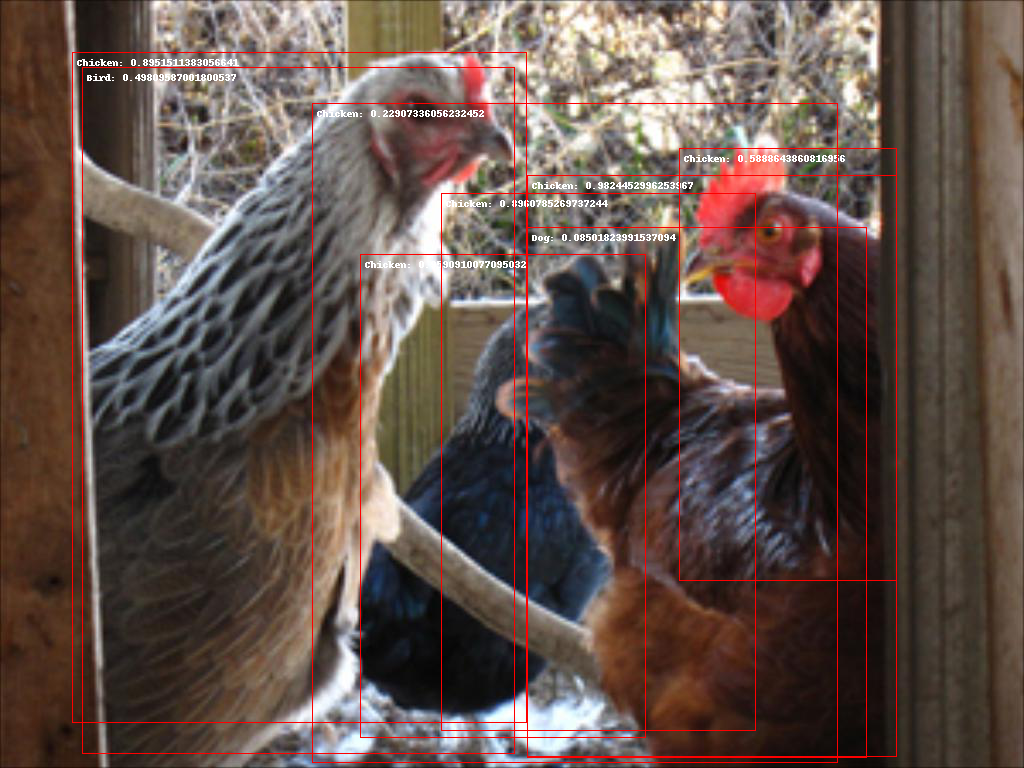

In [35]:
# convert the image, which has been rescaled to 0-1 and had the channels flipped
pred_img = Image.fromarray(img.mul(255).permute(1, 2, 0).byte().numpy())
draw = ImageDraw.Draw(pred_img)

for i in range(len(img_preds["boxes"])):
    if i in keep_idx:
        x1, y1, x2, y2 = img_preds["boxes"][i]
        label = int(img_preds["labels"][i])
        score = float(img_preds["scores"][i])

        draw.rectangle(((x1, y1), (x2, y2)), outline="red")
        text = f'{dataset.cat2name[label]}: {score}'
        draw.text((x1+5, y1+5), text)

display(pred_img)

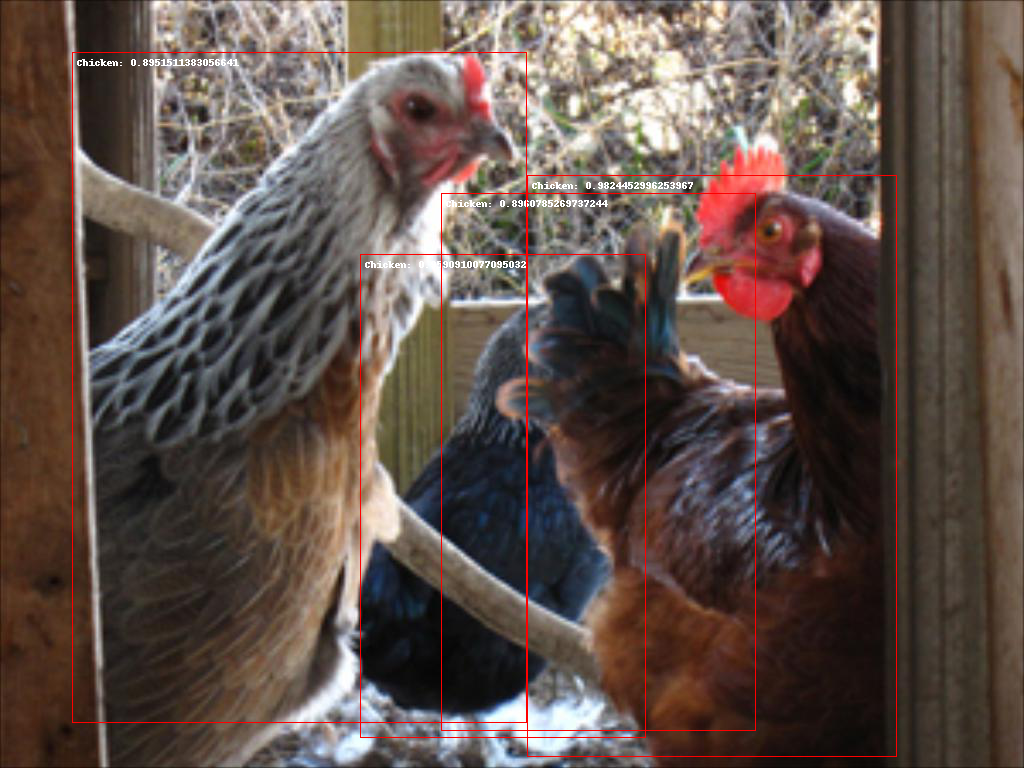

In [36]:
det_threshold = 0.7

# convert the image, which has been rescaled to 0-1 and had the channels flipped
pred_img = Image.fromarray(img.mul(255).permute(1, 2, 0).byte().numpy())
draw = ImageDraw.Draw(pred_img)

for i in range(len(img_preds["boxes"])):
    if i in keep_idx:
        x1, y1, x2, y2 = img_preds["boxes"][i]
        label = int(img_preds["labels"][i])
        score = float(img_preds["scores"][i])

        # filter out non-confident detections
        if score > det_threshold:
            draw.rectangle(((x1, y1), (x2, y2)), outline="red")
            text = f'{dataset.cat2name[label]}: {score}'
            draw.text((x1+5, y1+5), text)

display(pred_img)

In [37]:
# save model weights
save_path = os.path.join(base_folder, "c1_weights.pth")
torch.save(model.state_dict(), save_path)

# Evaluation on Val Set

In [38]:
with open(val_annotation) as json_file:
    val_data = json.load(json_file)

model.eval()
detections = []
with torch.no_grad():
    for image in val_data["images"]:
        img_name = image["file_name"]
        img_id = image["id"]

        img = Image.open(os.path.join(til_root, 'images', img_name)).convert('RGB')
        img_tensor = transforms.ToTensor()(img)

        preds = model([img_tensor.to(device)])[0]

        for i in range(len(preds["boxes"])):
            x1, y1, x2, y2 = preds["boxes"][i]
            label = int(preds["labels"][i])
            score = float(preds["scores"][i])

            left = int(x1)
            top = int(y1)
            width = int(x2 - x1)
            height = int(y2 - y1)

            detections.append({'image_id':img_id, 'category_id':label, 'bbox':[left, top, width, height], 'score':score})

In [ ]:
validation_json = os.path.join(base_folder, "validation_preds.json")
with open(validation_json, 'w') as f:
    json.dump(detections, f)

In [41]:
# Get evaluation score against validation set to make sure your prediction json file is in the correct format
coco_gt = COCO(val_annotation)
coco_dt = coco_gt.loadRes(validation_json)
cocoEval = COCOeval(cocoGt=coco_gt, cocoDt=coco_dt, iouType='bbox')
cocoEval.evaluate()
cocoEval.accumulate()
cocoEval.summarize()

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


NameError: ignored

# Generate Prediction on Test Set

In [ ]:
# You should already have uploaded the testing images onto your google drive.

testing_images_path = os.path.join(base_folder, "c1_test_release.zip") # change this path to the zip file for the test images
!unzip $testing_images_path

In [ ]:
til_test_root = "/content/c1_test_release/" # extracted testing images path
test_img_root = os.path.join(til_test_root, "images")
img_dir = os.scandir(test_img_root)

In [ ]:
# load model weights (if not using the current trained model)
model.load_state_dict(torch.load(save_path, map_location=device))
model.to(device)
model.eval()

In [ ]:
img = Image.open(next(img_dir).path).convert('RGB')
draw = ImageDraw.Draw(img)
det_threshold = 0.5

# do the prediction
with torch.no_grad():
    img_tensor = transforms.ToTensor()(img)
    img_preds = model([img_tensor.to(device)])[0]

for i in range(len(img_preds["boxes"])):
    x1, y1, x2, y2 = img_preds["boxes"][i]
    label = int(img_preds["labels"][i])
    score = float(img_preds["scores"][i])

    # filter out non-confident detections
    if score > det_threshold:
        draw.rectangle(((x1, y1), (x2, y2)), outline="red")
        text = f'{dataset.cat2name[label]}: {score}'
        draw.text((x1+5, y1+5), text)

display(img)

# Submission of Results

In [ ]:
# generate detections on the folder of test images (this will be used for submission)
detections = []
with torch.no_grad():
    for image in img_dir:
        img_id = int(image.name.split('.')[0])

        img = Image.open(image.path).convert('RGB')
        img_tensor = transforms.ToTensor()(img)

        preds = model([img_tensor.to(device)])[0]

        for i in range(len(preds["boxes"])):
            x1, y1, x2, y2 = preds["boxes"][i]
            label = int(preds["labels"][i])
            score = float(preds["scores"][i])

            left = int(x1)
            top = int(y1)
            width = int(x2 - x1)
            height = int(y2 - y1)

            detections.append({'image_id':img_id, 'category_id':label, 'bbox':[left, top, width, height], 'score':score})

In [ ]:
test_pred_json = os.path.join(base_folder, "test_preds.json")
with open(test_pred_json, 'w') as f:
    json.dump(detections, f)

# Check Submission on JSON Format

In [ ]:
sample_json_path = os.path.join(til_test_root, "c1_test_sample.json")

coco_gt = COCO(sample_json_path)
coco_dt = coco_gt.loadRes(test_pred_json)
cocoEval = COCOeval(cocoGt=coco_gt, cocoDt=coco_dt, iouType='bbox')
cocoEval.evaluate()
cocoEval.accumulate()
cocoEval.summarize()